<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/voyager_1_light_day.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Voyager 1, One Light-Day From Earth: Distances with SPICE

On **November 18, 2026, at 10:16:07 UTC**, NASA's Voyager 1 became so far away that light, and every radio command we send, needs a full day to get there. Launched in September 1977, it has flown for 49 years to cover the distance light covers in one day.

**A light-day** is the distance light travels in one day. The speed of light $c$ is exact by the definition of the metre, so a light-day is exact, too:

$$1\ \text{light-day} = c \cdot 86\,400\ \text{s} = 299\,792.458\ \tfrac{\text{km}}{\text{s}} \cdot 86\,400\ \text{s} \approx 25.9\ \text{billion km}$$

One light-hour is a 24th of it, about 1.08 billion km.

**The astronomical unit** (AU) is the other ruler of the Solar System: 149,597,870.7 km, about the mean distance between the Earth and the Sun. Since 2012 it's a fixed number (IAU 2012 Resolution B2).

**Which distance?** NASA measures from the centre of the Earth, at one instant: the geometric distance, ignoring that light needs time to travel. That's what we compute here. The signal that arrives from Voyager at that moment left it a day earlier, when it was about 1.5 million km closer.

To compute where Voyager 1 is, we use [SPICE](https://naif.jpl.nasa.gov/naif/), NASA's toolkit for the geometry of space missions, with its Python wrapper [spiceypy](https://github.com/AndrewAnnex/SpiceyPy). We'll answer three questions:

1. How far is Voyager 1 from the Earth and from the Sun at NASA's moment, in AU and in light-hours?
2. When exactly does it reach one light-day from the Earth, and from the Sun?
3. How did the distances grow since 1977, and why does the distance from the Earth wobble?

In [1]:
!pip install -q --disable-pip-version-check spiceypy  # Colab has numpy, pandas and matplotlib already
import pathlib
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spiceypy

plt.style.use('dark_background')

## Get the Data

SPICE reads its data from files called kernels. We need four, about 42 MB in total. The next cell downloads them into a folder `data/kernels/` next to this notebook, on your computer or on Google Colab, unless they're there already:

| Kernel | What it holds | Download |
|---|---|---|
| `naif0012.tls` | The leap seconds, to convert UTC into the ephemeris time SPICE computes with | [NAIF](https://naif.jpl.nasa.gov/pub/naif/generic_kernels/lsk/naif0012.tls) |
| `de440s.bsp` | The positions of the Sun, the planets and the Moon from 1849 to 2150 (JPL DE440) | [NAIF](https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/planets/de440s.bsp) |
| `Voyager_1.a54206u_V0.2_merged.bsp` | Voyager 1's path from the launch on, from NAIF's Voyager archive. After 1980 it's a prediction from 1990 | [NAIF](https://naif.jpl.nasa.gov/pub/naif/VOYAGER/kernels/spk/Voyager_1.a54206u_V0.2_merged.bsp) |
| `vgr1.x2100.bsp` | Voyager 1's path from 1981 to 2099, refitted to all the tracking data in 2022. JPL's Horizons system uses the same solution | [JPL SSD](https://ssd.jpl.nasa.gov/ftp/eph/spacecraft/vgr1.x2100.bsp) |

Why two Voyager kernels? The older one starts at the launch, but its prediction drifts: it puts the light-day crossing 23 minutes too early. The 2022 refit matches NASA's time to the second, but it only starts in 1981. So we load both, in the order of the table, the refit last: where two kernels overlap, SPICE uses the one loaded last.

In [2]:
# Download the kernels into data/kernels/, unless they're there already, and load them in this order
KERNEL_URLS = ["https://naif.jpl.nasa.gov/pub/naif/generic_kernels/lsk/naif0012.tls",
               "https://naif.jpl.nasa.gov/pub/naif/generic_kernels/spk/planets/de440s.bsp",
               "https://naif.jpl.nasa.gov/pub/naif/VOYAGER/kernels/spk/Voyager_1.a54206u_V0.2_merged.bsp",
               "https://ssd.jpl.nasa.gov/ftp/eph/spacecraft/vgr1.x2100.bsp"]

kernel_dir = pathlib.Path("data/kernels")
kernel_dir.mkdir(parents=True, exist_ok=True)
for kernel_url in KERNEL_URLS:
    kernel_path = kernel_dir / kernel_url.split("/")[-1]
    if not kernel_path.exists():
        urllib.request.urlretrieve(kernel_url, kernel_path)
    spiceypy.furnsh(str(kernel_path))

## Our Rulers

SPICE knows the speed of light. From it, we get the light-hour and the light-day in km.

In [3]:
# The speed of light in km/s, and the light-hour and the light-day in km
SPEED_OF_LIGHT_KM_S = spiceypy.clight()
ONE_LH_KM = SPEED_OF_LIGHT_KM_S * 3600.0
ONE_LD_KM = ONE_LH_KM * 24.0

# The astronomical unit in km (IAU 2012 Resolution B2)
ONE_AU_KM = 149_597_870.7

print(f"One light-hour in km: {ONE_LH_KM:,.1f}")
print(f"One light-day in km: {ONE_LD_KM:,.1f} (NASA: 25,902,068,356)")

One light-hour in km: 1,079,252,848.8
One light-day in km: 25,902,068,371.2 (NASA: 25,902,068,356)


## Voyager 1 at NASA's Moment

SPICE computes in ephemeris time (ET): seconds after January 1, 2000, 12:00 TDB. `utc2et` converts NASA's moment into it, leap seconds included. `spkpos` then gives Voyager 1's position as seen from an observer. We ask for the geometric position (`abcorr="NONE"`, no light-time correction), as NASA does, from the centre of the Earth and from the centre of the Sun.

In [4]:
# Convert NASA's moment, 10:16:07 UTC on 2026 November 18, into ephemeris time
et_nasa = spiceypy.utc2et("2026-11-18T10:16:07")

# Compute the distance of Voyager 1 from the Earth and from the Sun at this moment
for observer in ["EARTH", "SUN"]:
    pos_km, _ = spiceypy.spkpos(targ="VOYAGER 1", et=et_nasa, ref="ECLIPJ2000",
                                abcorr="NONE", obs=observer)
    dist_km = spiceypy.vnorm(pos_km)
    print(f"{observer.title()} - Voyager 1: {dist_km / ONE_AU_KM:.2f} AU, "
          f"{dist_km / ONE_LH_KM:.4f} light-hours")

Earth - Voyager 1: 173.14 AU, 24.0000 light-hours
Sun - Voyager 1: 172.39 AU, 23.8953 light-hours


Exactly 24 light-hours from the Earth: our kernels agree with NASA. And we can verify the AU with NASA's [Horizons](https://ssd.jpl.nasa.gov/horizons/) system, which gives 173.14 AU from the Earth's centre at the same moment.

From the Sun, Voyager 1 is about 0.8 AU closer. Why? In November, the Earth is on the far side of the Sun as seen from Voyager 1.

## When Exactly?

Instead of guessing a time and checking it, we let SPICE search for it. Its geometry finder `gfdist` looks for the moments when a distance equals a value, inside a search window. It steps through the window and then refines every crossing it finds. The step must be shorter than the time between two turns of the distance, so it can't jump over a crossing: we take 30 days, because the Earth's orbit turns the distance around twice a year.

We search all of 2026 and 2027. If Voyager crossed the line more than once in that window, we'd see more than one moment.

In [5]:
# Set the search window: from the start of 2026 to the start of 2028
search_window = spiceypy.cell_double(2)
spiceypy.wninsd(spiceypy.utc2et("2026-01-01"), spiceypy.utc2et("2028-01-01"), search_window)

# Search for the moments when Voyager 1 is one light-day from the Earth, and from the Sun
for observer in ["EARTH", "SUN"]:
    crossings = spiceypy.cell_double(20)
    spiceypy.gfdist(target="VOYAGER 1", abcorr="NONE", obsrvr=observer, relate="=",
                    refval=ONE_LD_KM, adjust=0.0, step=30.0 * 86400.0, nintvls=10,
                    cnfine=search_window, result=crossings)
    for k in range(spiceypy.wncard(crossings)):
        et_cross, _ = spiceypy.wnfetd(crossings, k)
        print(f"One light-day from the {observer.title()}: {spiceypy.et2utc(et_cross, 'C', 1)} UTC")

One light-day from the Earth: 2026 NOV 18 10:16:07.2 UTC
One light-day from the Sun: 2027 FEB 03 21:38:59.3 UTC


NASA's time, [10:16:07 UTC](https://science.nasa.gov/mission/voyager/voyager-1/voyager-1-what-is-a-light-day/), to the second. Each search finds a single moment: once Voyager 1 is a light-day away from us, it stays there. From the Sun, it gets there about 2.5 months later.

## From 1977 to 2030

Now the whole flight, one position per day. `spkpos` also takes an array of times, so one call per observer is enough. Our data starts a few days after the launch on September 5, 1977, safely inside the NAIF kernel's coverage.

In [6]:
# Create an array of ephemeris times, one per day, from September 1977 to the end of 2030
et_days = np.arange(spiceypy.utc2et("1977-09-08"), spiceypy.utc2et("2030-12-31"), 86400.0)

# Store the date and the distances from the Earth and the Sun in a dataframe, in AU and in light-hours
voyager_df = pd.DataFrame({"date": [spiceypy.et2datetime(et) for et in et_days]})
for observer in ["EARTH", "SUN"]:
    pos_km, _ = spiceypy.spkpos("VOYAGER 1", et_days, "ECLIPJ2000", "NONE", observer)
    voyager_df[f"{observer.lower()}_au"] = np.linalg.norm(pos_km, axis=1) / ONE_AU_KM
    voyager_df[f"{observer.lower()}_lh"] = np.linalg.norm(pos_km, axis=1) / ONE_LH_KM

voyager_df.tail()

,date,earth_au,earth_lh,sun_au,sun_lh
19468,2030-12-26 23:59:38.998749+00:00,187.768418,26.027039,187.001635,25.920753
19469,2030-12-27 23:59:38.998721+00:00,187.773676,26.027767,187.011371,25.922102
19470,2030-12-28 23:59:38.998692+00:00,187.778697,26.028463,187.021107,25.923452
19471,2030-12-29 23:59:38.998663+00:00,187.783484,26.029127,187.030843,25.924802
19472,2030-12-30 23:59:38.998634+00:00,187.788038,26.029758,187.040579,25.926151


## Visualisation

The distance from the Sun grows smoothly: after the Saturn flyby in November 1980, Voyager 1 coasts at about 17 km/s, 3.6 AU a year. The light-hours are on the left axis, the AU on the right.

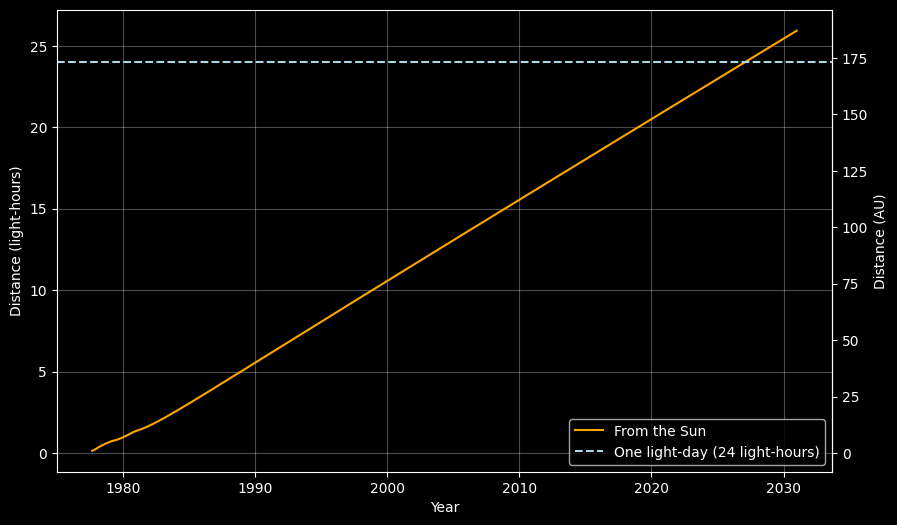

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(voyager_df["date"], voyager_df["sun_lh"], color="orange", label="From the Sun")
ax.axhline(24.0, color="lightblue", ls="--", label="One light-day (24 light-hours)")
ax.set_xlabel("Year")
ax.set_ylabel("Distance (light-hours)")
ax.grid(alpha=0.3)
ax.legend()

# Add a second y-axis on the right that shows the same distance in AU
ax.secondary_yaxis("right", functions=(lambda lh: lh * ONE_LH_KM / ONE_AU_KM,
                                       lambda au: au * ONE_AU_KM / ONE_LH_KM)).set_ylabel("Distance (AU)")
plt.show()

Now let's zoom into 2025 to 2028, and add the distance from the Earth. It wobbles around the distance from the Sun, because the Earth circles the Sun once a year: up to 1 AU, or about 8.3 light-minutes, closer to Voyager 1 and then farther. But Voyager 1 climbs about 3.6 AU a year, so each year's lowest point is higher than the last one's: after November 18, 2026, the distance from the Earth never drops back under a light-day.

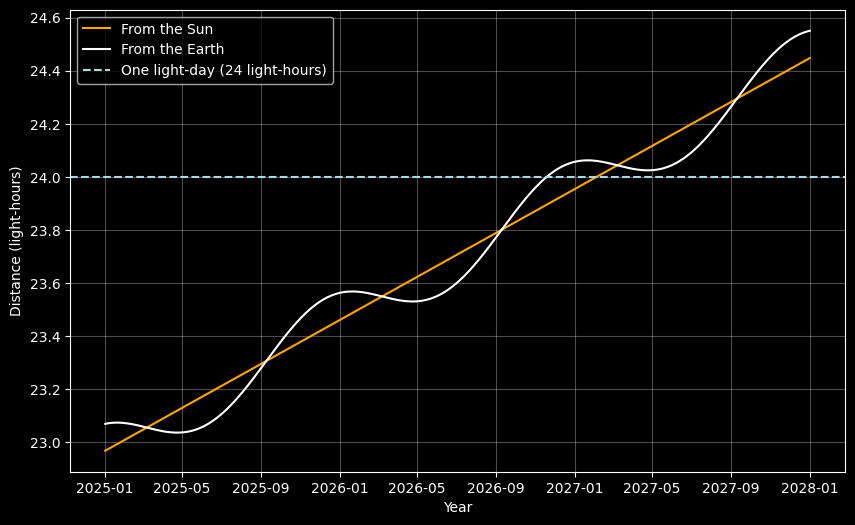

In [8]:
# Select the years 2025 to 2027
zoom_df = voyager_df[voyager_df["date"].dt.year.between(2025, 2027)]

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(zoom_df["date"], zoom_df["sun_lh"], color="orange", label="From the Sun")
ax.plot(zoom_df["date"], zoom_df["earth_lh"], color="white", label="From the Earth")
ax.axhline(24.0, color="lightblue", ls="--", label="One light-day (24 light-hours)")
ax.set_xlabel("Year")
ax.set_ylabel("Distance (light-hours)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Take-Aways

* **24 light-hours from the Earth at 10:16:07 UTC on November 18, 2026:** 173.14 AU, about 25.9 billion km. SPICE and NASA agree to the second, with JPL's 2022 refit of Voyager 1's path.
* **From the Sun, 24 light-hours on February 3, 2027,** about 2.5 months later, because in November the Earth is on Voyager's far side of the Sun.
* **The Earth's orbit makes the distance wobble** by up to ±1 AU around the distance from the Sun. Voyager's climb of about 3.6 AU a year wins, so it never comes back under a light-day.
* **The kernel matters:** load only `Voyager_1.a54206u_V0.2_merged.bsp`, NAIF's prediction from 1990, and the crossing moves 23 minutes earlier. 36 years of extrapolation add up to about 35,500 km.
* **Try it yourself:** Voyager 2's ID in SPICE is -32 (`VOYAGER 2`). NASA says it reaches one light-day from the Earth in November 2035. Download `vgr2.x2100.bsp` from the same JPL folder and find the moment with `gfdist`.

## Sources

* NASA (2026): Voyager 1: What Is a Light-Day? Updated 2026-11-12. https://science.nasa.gov/mission/voyager/voyager-1/voyager-1-what-is-a-light-day/
* NASA (2026): Where Are Voyager 1 and Voyager 2 Now? Updated 2026-11-15. https://science.nasa.gov/mission/voyager/where-are-voyager-1-and-voyager-2-now/
* JPL Horizons System, Voyager 1 (-31), trajectory Voyager_1_ST+refit2022_m. https://ssd.jpl.nasa.gov/horizons/
* Park, Folkner, Williams & Boggs (2021): The JPL Planetary and Lunar Ephemerides DE440 and DE441. The Astronomical Journal 161, 105. https://doi.org/10.3847/1538-3881/abd414
* Acton (1996): Ancillary data services of NASA's Navigation and Ancillary Information Facility. Planetary and Space Science 44, 65–70. https://doi.org/10.1016/0032-0633(95)00107-7
* Annex, Pearson, Seignovert et al. (2020): SpiceyPy: a Pythonic Wrapper for the SPICE Toolkit. Journal of Open Source Software 5, 2050. https://doi.org/10.21105/joss.02050
* IAU (2012): Resolution B2, on the re-definition of the astronomical unit of length. https://www.iau.org/static/resolutions/IAU2012_English.pdf
* BIPM (2019): The International System of Units (SI), 9th edition. https://www.bipm.org/en/publications/si-brochure